# 1.Import Libraries 

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2.Load Dataset 

In [128]:
import os
os.listdir("/kaggle/input")

['datasets']

In [129]:
os.listdir("/kaggle/input/datasets")

['razanihababdellatif']

In [130]:
os.listdir("/kaggle/input/datasets/razanihababdellatif")

['bank-marketing-and-customer-behavior-dataset']

In [131]:
df = pd.read_csv("/kaggle/input/datasets/razanihababdellatif/bank-marketing-and-customer-behavior-dataset/Bank_Marketing_Dataset.csv")

# 3. Data Understanding

Before cleaning the data, we first explore the dataset to understand its structure, dimensions, data types, and overall quality.


In [132]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,Class
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,1
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,1
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,1
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,1
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,1


In [133]:
df.shape

(45211, 17)

In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   V1      45211 non-null  int64 
 1   V2      45211 non-null  object
 2   V3      45211 non-null  object
 3   V4      45211 non-null  object
 4   V5      45211 non-null  object
 5   V6      45211 non-null  int64 
 6   V7      45211 non-null  object
 7   V8      45211 non-null  object
 8   V9      45211 non-null  object
 9   V10     45211 non-null  int64 
 10  V11     45211 non-null  object
 11  V12     45211 non-null  int64 
 12  V13     45211 non-null  int64 
 13  V14     45211 non-null  int64 
 14  V15     45211 non-null  int64 
 15  V16     45211 non-null  object
 16  Class   45211 non-null  int64 
dtypes: int64(8), object(9)
memory usage: 5.9+ MB


In [135]:
df.describe()

,V1,V6,V10,V12,V13,V14,V15,Class
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323,1.116985
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000,1.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000,1.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000,1.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000,1.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000,2.000000


In [136]:
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'Class'],
      dtype='object')

# 4.Rename Columns

Rename the dataset columns to meaningful names for easier understanding and analysis.

In [137]:
df.columns = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "balance",
    "housing",
    "loan",
    "contact",
    "day",
    "month",
    "duration",
    "campaign",
    "pdays",
    "previous",
    "poutcome",
    "subscribed"
]

In [138]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'subscribed'],
      dtype='object')

# 5.Data Quality Assessment

In this section, we evaluate the quality of the dataset before performing any cleaning operations. We check for missing values, duplicate records, data types, unique values, inconsistent categories, and potential outliers.

In [139]:
df.isnull().sum()

age           0
job           0
marital       0
education     0
default       0
balance       0
housing       0
loan          0
contact       0
day           0
month         0
duration      0
campaign      0
pdays         0
previous      0
poutcome      0
subscribed    0
dtype: int64

**Observation:**

No missing values were found in the dataset.

In [140]:
df.duplicated().sum()

np.int64(0)

**Observation:**

No duplicate records were found in the dataset.

In [141]:
df.dtypes

age            int64
job           object
marital       object
education     object
default       object
balance        int64
housing       object
loan          object
contact       object
day            int64
month         object
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome      object
subscribed     int64
dtype: object

**Observation:**

The data types are appropriate for their corresponding features.

In [142]:
df.nunique()

age             77
job             12
marital          3
education        4
default          2
balance       7168
housing          2
loan             2
contact          3
day             31
month           12
duration      1573
campaign        48
pdays          559
previous        41
poutcome         4
subscribed       2
dtype: int64

**Observation:**

The number of unique values in each column helps identify categorical and numerical features.

In [143]:
categorical_columns = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
    "subscribed"
]

for col in categorical_columns:
    print(f"\n{col.upper()}")
    print(df[col].unique())


JOB
['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']

MARITAL
['married' 'single' 'divorced']

EDUCATION
['tertiary' 'secondary' 'unknown' 'primary']

DEFAULT
['no' 'yes']

HOUSING
['yes' 'no']

LOAN
['no' 'yes']

CONTACT
['unknown' 'cellular' 'telephone']

MONTH
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

POUTCOME
['unknown' 'failure' 'other' 'success']

SUBSCRIBED
[1 2]


In [144]:
df["subscribed"] = df["subscribed"].replace({
    1: "Yes",
    2: "No"
})

In [145]:
df["subscribed"].value_counts()

subscribed
Yes    39922
No      5289
Name: count, dtype: int64

### Detect Outliers

Visualize numerical features using boxplots to identify potential outliers before data cleaning.

In [146]:
numerical_columns = [
    "age",
    "balance",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

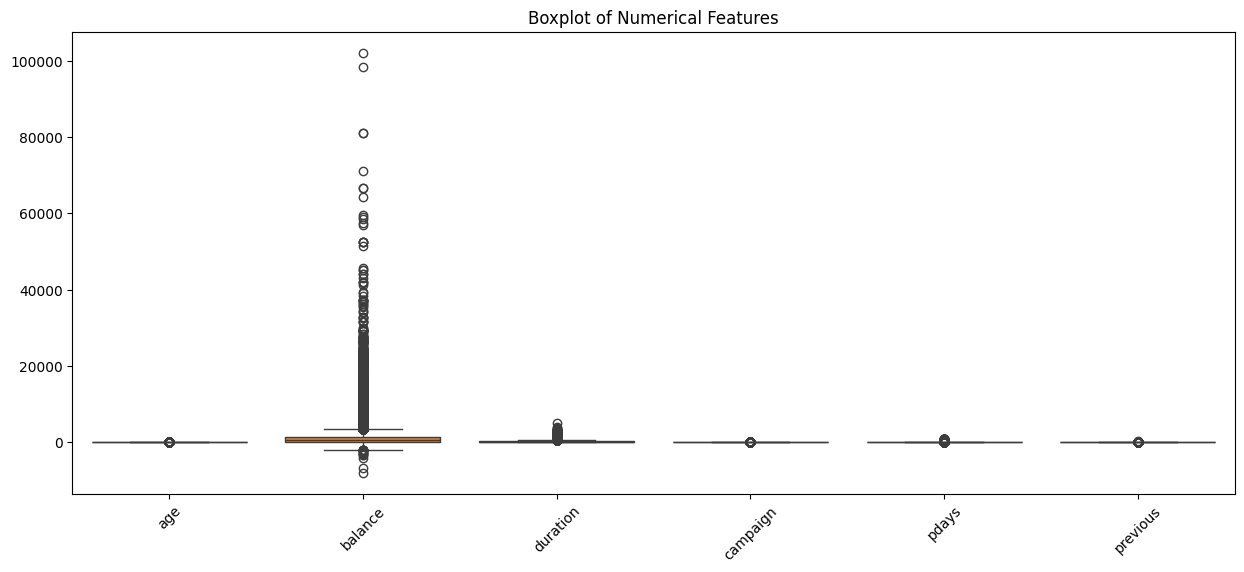

In [147]:
plt.figure(figsize=(15,6))

sns.boxplot(data=df[numerical_columns])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)

plt.show()

### Observation

The boxplots show the presence of outliers in several numerical features, particularly **balance**, **duration**, **campaign**, **pdays**, and **previous**.

These values appear to be valid business observations rather than data entry errors. Therefore, no outliers were removed from the dataset.

### Cleaning Summary 

- Column names were renamed for better readability.
- No missing values were found.
- No duplicate records were found.
- The target variable was converted from numeric labels to meaningful categories (Yes/No).
- Outliers were retained because they represent valid business observations.

### Handling Unkown Values

In [148]:
# Mode Imputation for 'job' and 'education'
df['job'] = df['job'].replace('unknown', df['job'].mode()[0])
df['education'] = df['education'].replace('unknown', df['education'].mode()[0])

# Verify that 'unknown' has been replaced in job & education
print("Remaining 'unknown' in job:", (df['job'] == 'unknown').sum())
print("Remaining 'unknown' in education:", (df['education'] == 'unknown').sum())

Remaining 'unknown' in job: 0
Remaining 'unknown' in education: 0


# 6.Exploratory Data Analysis (EDA)¶

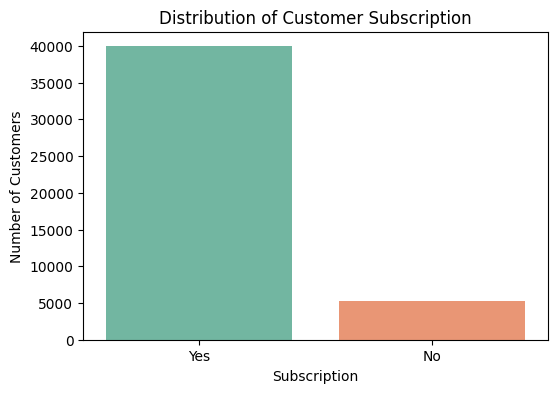

In [149]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="subscribed",
    hue="subscribed",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Customer Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

### Observationn 
The chart shows that most customers did not subscribe, while a smaller number subscribed. This means that the "No" category is more common than the "Yes" category.

In [150]:
(df["subscribed"].value_counts(normalize=True)*100).round(2)

subscribed
Yes    88.3
No     11.7
Name: proportion, dtype: float64

### Interpretation:
The percentages confirm that most customers did not subscribe to the term deposit, while only a small percentage subscribed.

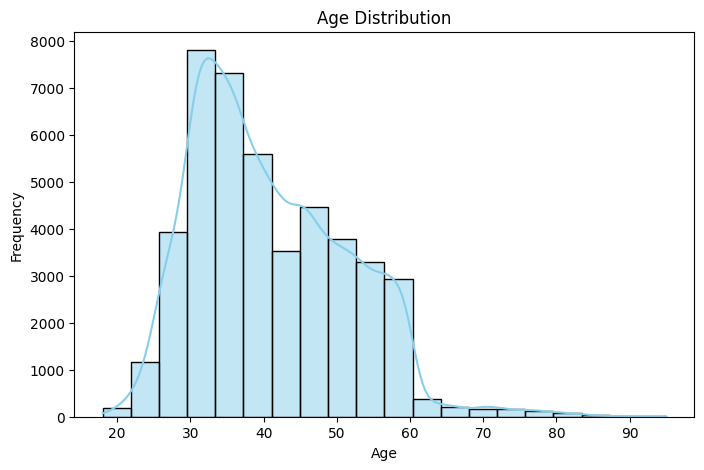

In [151]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

### Interpretation:
The chart shows that most customers are middle-aged, while fewer customers are very young or very old. This indicates that the bank's customers are mainly from the middle-age group.

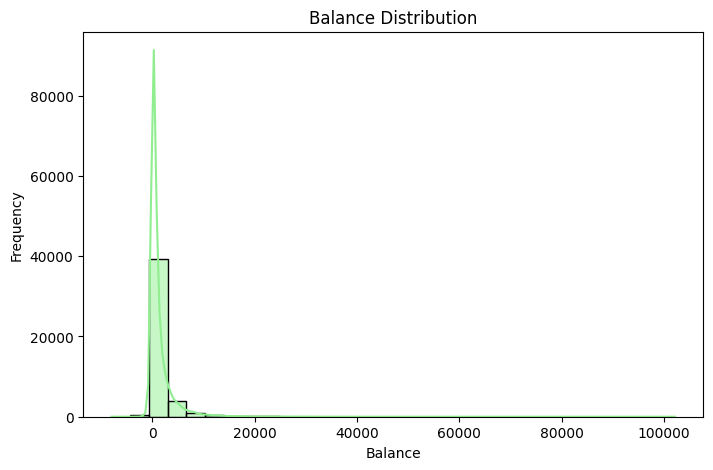

In [152]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="balance",
    bins=30,
    kde=True,
    color="lightgreen"
)

plt.title("Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Frequency")

plt.show()

### Interpretation

The chart shows that most customers have low account balances, while only a few customers have very high balances. This means that high balances are less common in the dataset.

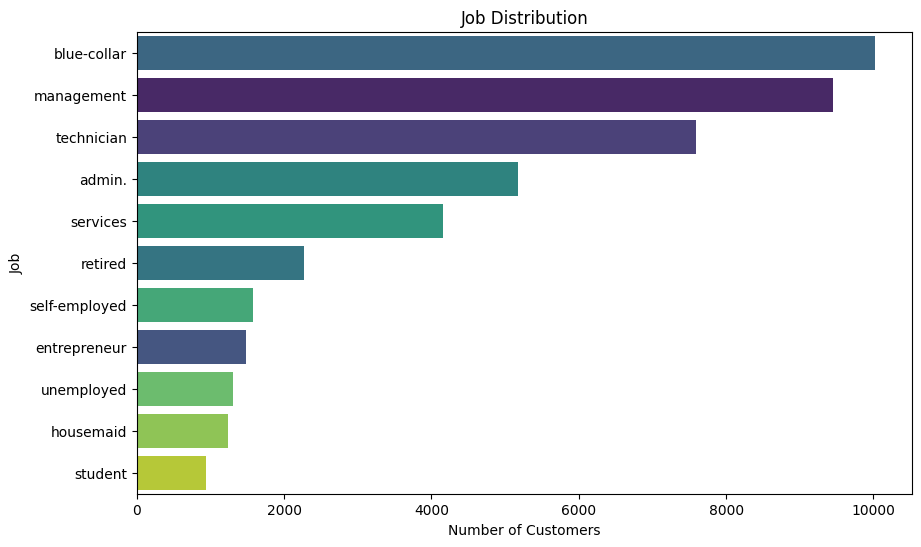

In [153]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="job",
    order=df["job"].value_counts().index,
    palette="viridis",
    hue="job",
    legend=False
)

plt.title("Job Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Job")

plt.show()

### Interpretation

The chart shows that some job categories have more customers than others. Management, blue-collar, and technician are among the most common jobs, while jobs such as student and unemployed have fewer customers.

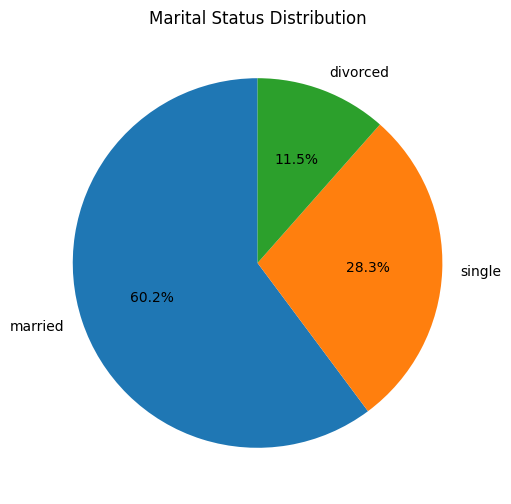

In [154]:
marital = df["marital"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    marital,
    labels=marital.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Marital Status Distribution")

plt.show()

### Interpretation

The pie chart shows that most customers are married, followed by single customers, while divorced customers make up the smallest group.

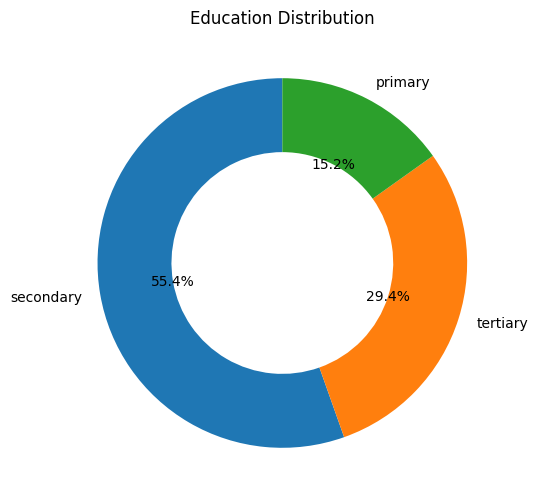

In [155]:
education = df["education"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    education,
    labels=education.index,
    autopct="%1.1f%%",
    wedgeprops={"width":0.4},
    startangle=90
)

plt.title("Education Distribution")

plt.show()

### Interpretation

The chart shows that most customers have a secondary education, followed by tertiary education, while primary education is the least common.

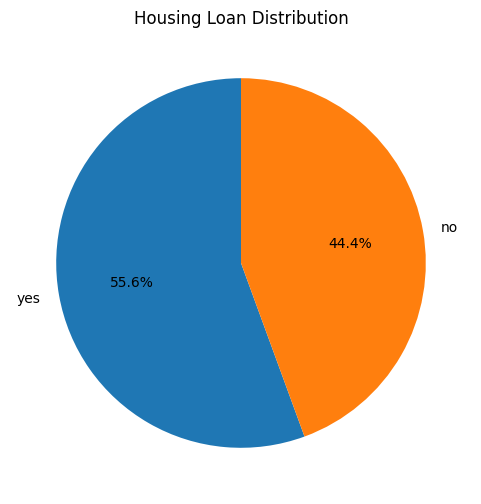

In [156]:
housing = df["housing"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    housing,
    labels=housing.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Housing Loan Distribution")

plt.show()

### Interpretation

The chart shows that most customers have a housing loan, while a smaller number of customers do not have a housing loan.

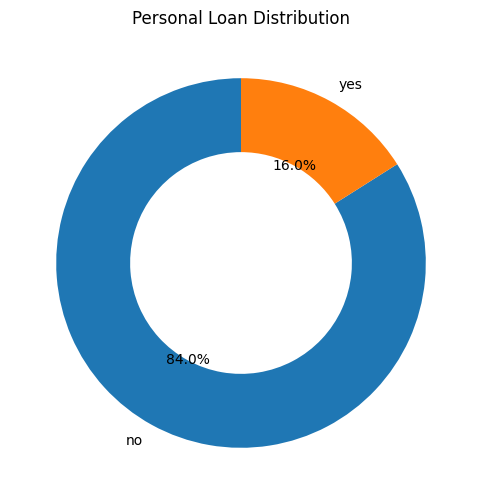

In [157]:
loan = df["loan"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    loan,
    labels=loan.index,
    autopct="%1.1f%%",
    wedgeprops={"width":0.4},
    startangle=90
)

plt.title("Personal Loan Distribution")

plt.show()

### Interpretation

The chart shows that most customers do not have a personal loan, while a smaller number of customers have a personal loan.

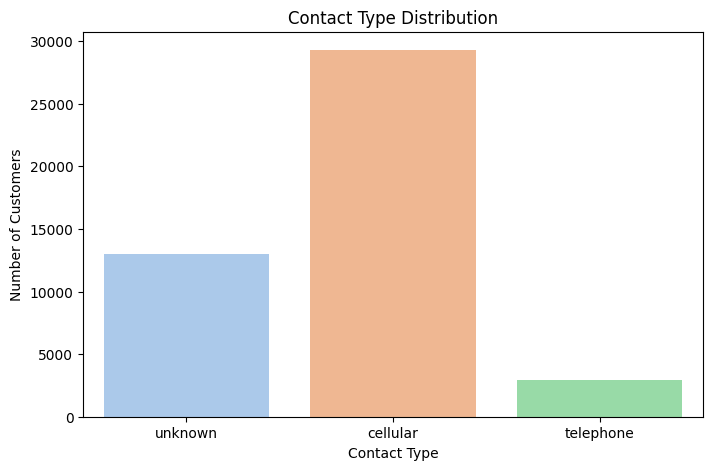

In [158]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="contact",
    palette="pastel",
    hue="contact",
    legend=False
)

plt.title("Contact Type Distribution")
plt.xlabel("Contact Type")
plt.ylabel("Number of Customers")

plt.show()

### Interpretation

The chart shows that cellular is the most common contact type, while telephone is used less often. This means that most customers were contacted through cellular communication.

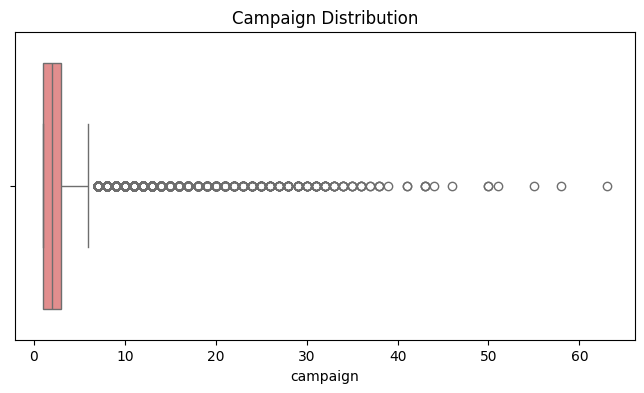

In [159]:
plt.figure(figsize=(8,4))

sns.boxplot(
    data=df,
    x="campaign",
    color="lightcoral"
)

plt.title("Campaign Distribution")

plt.show()

### Interpretation

The boxplot shows that most customers were contacted only a few times during the campaign. A few customers were contacted many times, which appear as outliers.

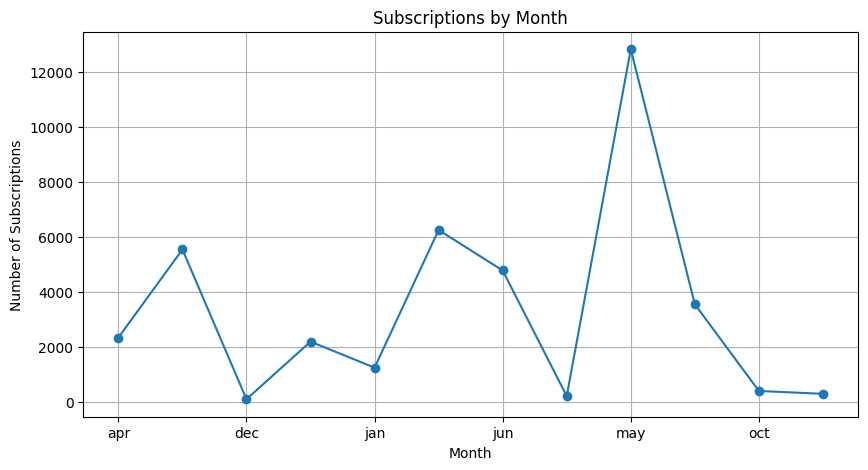

In [160]:
monthly = df.groupby("month")["subscribed"].value_counts().unstack()

monthly["Yes"].plot(
    marker="o",
    figsize=(10,5)
)

plt.title("Subscriptions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Subscriptions")

plt.grid(True)

plt.show()

### Interpretation

The line chart shows that the number of subscriptions changes from month to month. Some months have more subscriptions than others, indicating that customer responses vary throughout the year.

## Job vs Subscription

This chart compares customer subscription outcomes across different job categories.

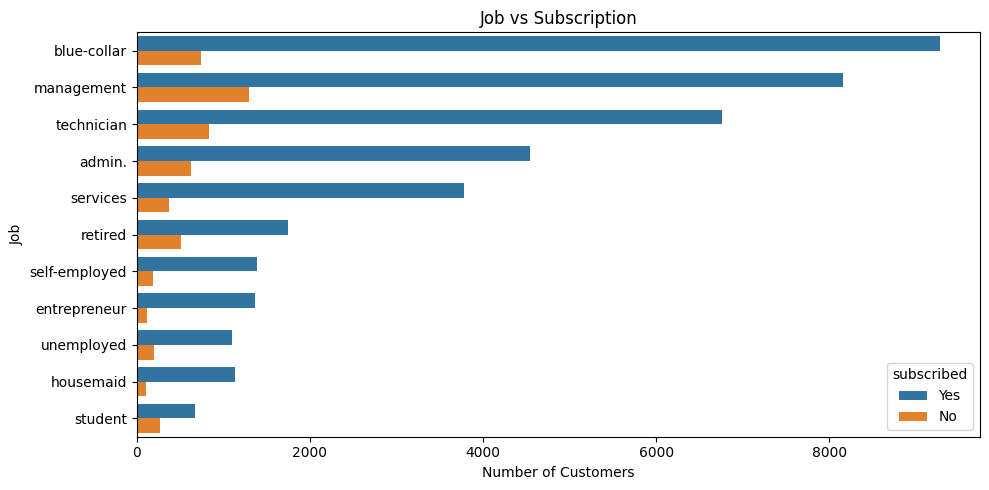

In [161]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    y="job",
    hue="subscribed",
    order=df["job"].value_counts().index
)

plt.title("Job vs Subscription")
plt.xlabel("Number of Customers")
plt.ylabel("Job")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that most job categories have more customers who did not subscribe than customers who subscribed. However, the number of subscriptions differs across different job types.

## Education vs Subscription

This visualization compares customer subscription outcomes across different education levels to examine whether education influences subscription behavior.

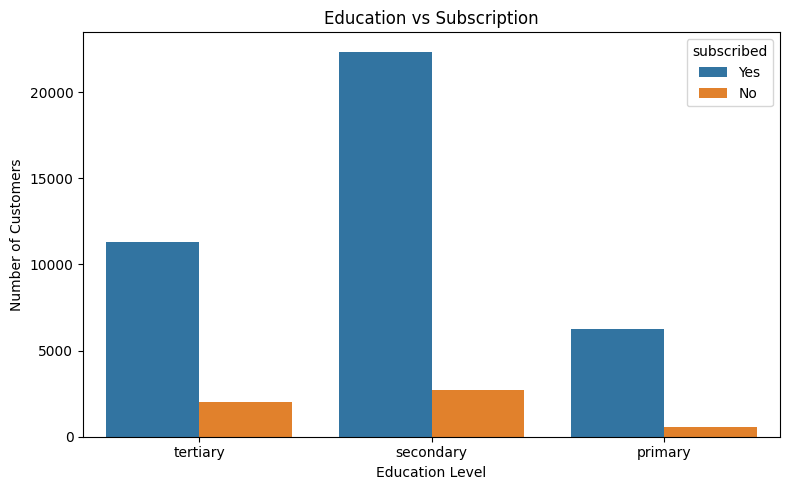

In [162]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="education",
    hue="subscribed"
)

plt.title("Education vs Subscription")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that customers with different education levels have different subscription rates. In all education groups, the number of customers who did not subscribe is higher than those who subscribed.

## Marital Status vs Subscription

This chart compares customer subscription outcomes across different marital status categories.

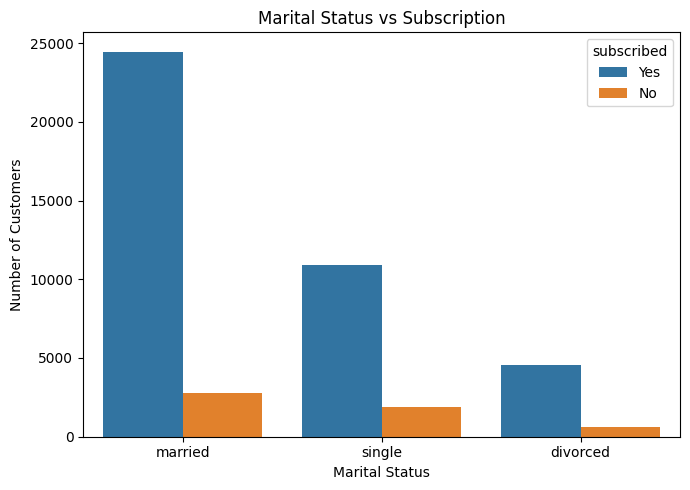

In [163]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="marital",
    hue="subscribed"
)

plt.title("Marital Status vs Subscription")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that married, single, and divorced customers have different subscription rates. In all marital status groups, the number of customers who did not subscribe is higher than the number who subscribed.

## Housing Loan vs Subscription

This visualization compares customer subscription outcomes based on whether the customer has a housing loan.

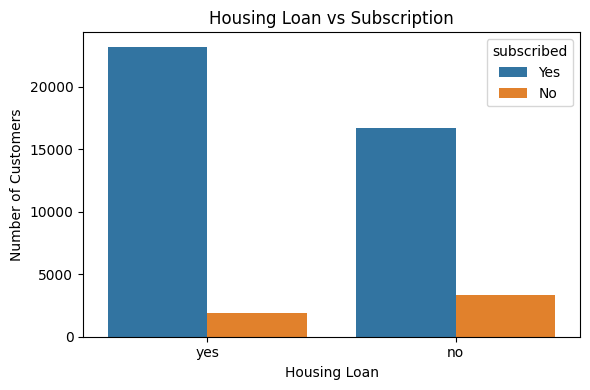

In [164]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="housing",
    hue="subscribed"
)

plt.title("Housing Loan vs Subscription")
plt.xlabel("Housing Loan")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that customers with and without housing loans have different subscription levels. In both groups, the number of customers who subscribed is higher than those who did not subscribe.

##  Personal Loan vs Subscription

This chart compares subscription outcomes between customers with and without personal loans.

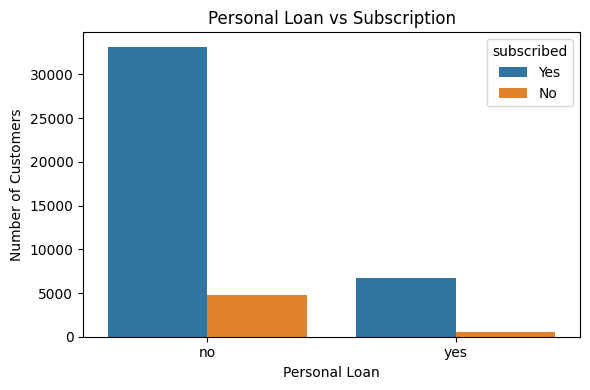

In [165]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="loan",
    hue="subscribed"
)

plt.title("Personal Loan vs Subscription")
plt.xlabel("Personal Loan")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that customers with and without personal loans have different subscription levels. In both groups, the number of customers who subscribed is higher than those who did not subscribe.

## Contact Type vs Subscription

This visualization shows customer subscription outcomes according to the communication method used during the marketing campaign.

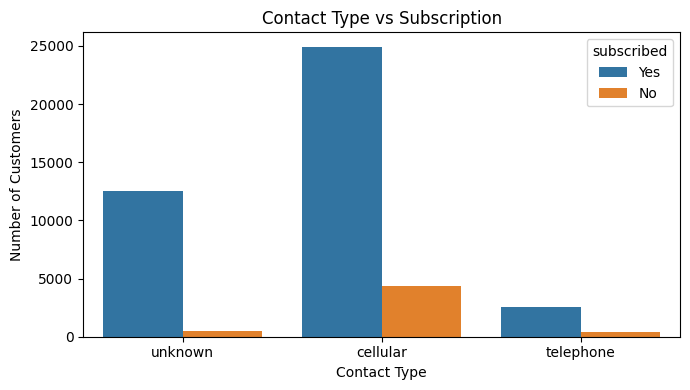

In [166]:
plt.figure(figsize=(7,4))

sns.countplot(
    data=df,
    x="contact",
    hue="subscribed"
)

plt.title("Contact Type vs Subscription")
plt.xlabel("Contact Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that customers contacted through different contact types have different subscription levels. In both contact types, the number of customers who subscribed is higher than those who did not subscribe.

## Call Duration vs Subscription

This strip plot shows the distribution of call duration for customers based on their subscription outcome.

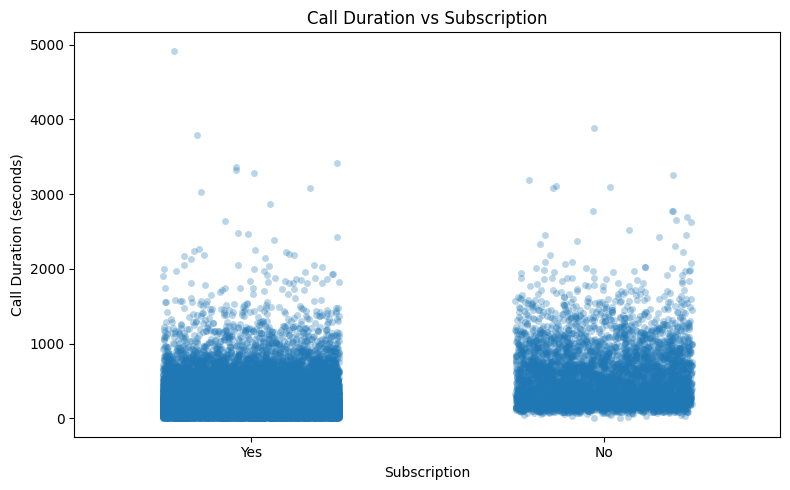

In [167]:
plt.figure(figsize=(8,5))

sns.stripplot(
    data=df,
    x="subscribed",
    y="duration",
    alpha=0.3,
    jitter=0.25
)

plt.title("Call Duration vs Subscription")
plt.xlabel("Subscription")
plt.ylabel("Call Duration (seconds)")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that customers who subscribed generally had longer call durations than those who did not subscribe. This suggests that longer calls are associated with higher subscription rates.

## Subscription by Month

This stacked bar chart shows customer subscriptions across different months.

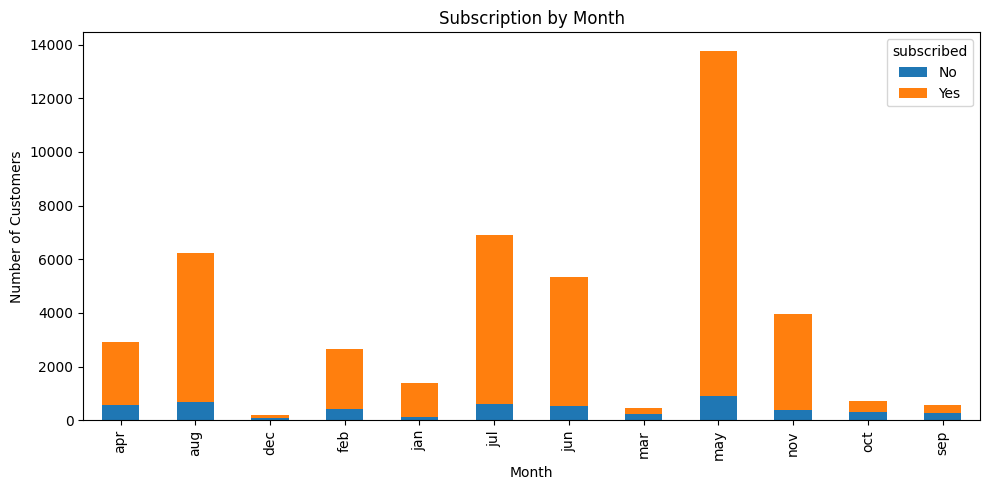

In [168]:
monthly = pd.crosstab(df["month"], df["subscribed"])

monthly.plot(
    kind="bar",
    stacked=True,
    figsize=(10,5)
)

plt.title("Subscription by Month")
plt.xlabel("Month")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that subscription levels vary across different months. In every month, the number of customers who subscribed is higher than the number who did not subscribe.

## Correlation Heatmap

The heatmap illustrates the correlation between numerical variables in the dataset.

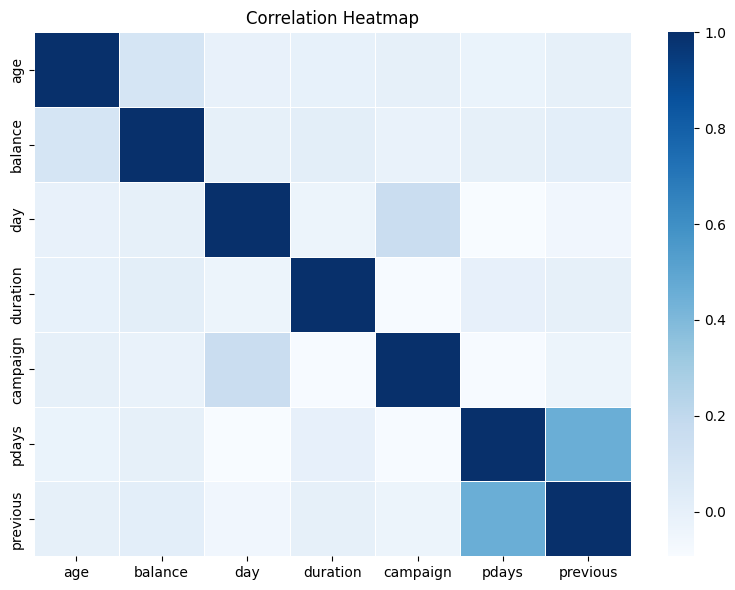

In [169]:
plt.figure(figsize=(8,6))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    cmap="Blues",
    annot=False,
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

### Interpretation

The heatmap shows the correlation between the numerical features in the dataset. Most variables have weak correlations, indicating that there are no strong linear relationships between them.

## Previous Campaign Outcome vs Subscription

This visualization examines the relationship between the outcome of the previous marketing campaign and customer subscription in the current campaign.

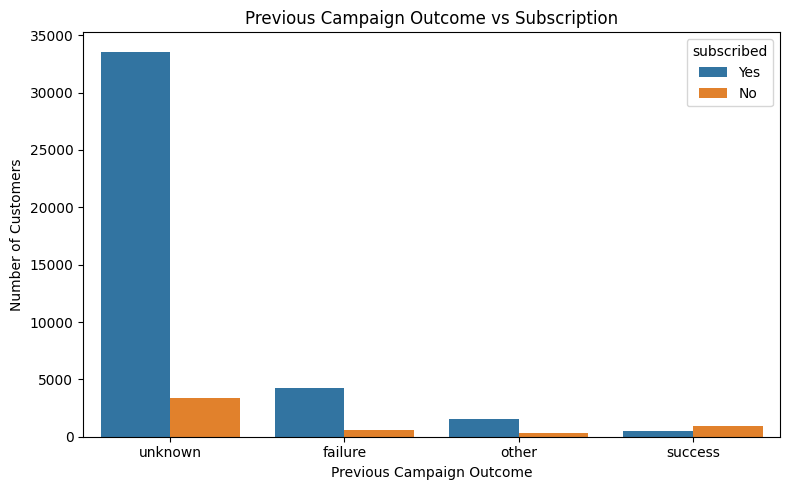

In [170]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="poutcome",
    hue="subscribed"
)

plt.title("Previous Campaign Outcome vs Subscription")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that subscription levels differ based on the outcome of the previous marketing campaign. Customers with different previous campaign outcomes have different subscription rates.

## Age Group vs Subscription

Customers are grouped into age categories to analyze how subscription behavior varies across different age groups.

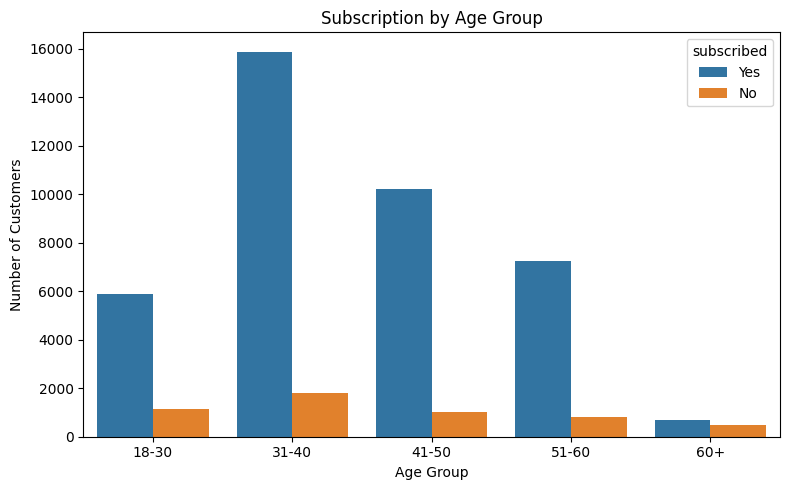

In [171]:
df["Age_Group"] = pd.cut(
    df["age"],
    bins=[18,30,40,50,60,100],
    labels=["18-30","31-40","41-50","51-60","60+"]
)

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Age_Group",
    hue="subscribed"
)

plt.title("Subscription by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that subscription levels vary across different age groups. Some age groups have more subscribed customers than others, indicating that age may influence subscription behavior.

### Save the Cleaned Dataset

The cleaned dataset was saved as **bank_marketing_cleaned.csv**. This file is ready for future analysis or machine learning tasks.

In [172]:
df.to_csv("bank_marketing_cleaned.csv", index=False)

#  Data Preprocessing for Machine Learning

Before building machine learning models, the dataset must be prepared by encoding categorical variables, separating the features from the target variable, and splitting the data into training and testing sets.

## Encoding Categorical Variables

Machine learning algorithms require numerical input. Therefore, categorical variables are converted into numerical values using one-hot encoding.

In [173]:
df_ml = df.copy()

df_ml = pd.get_dummies(df_ml, drop_first=True)

df_ml.head()

,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,subscribed_Yes,Age_Group_31-40,Age_Group_41-50,Age_Group_51-60,Age_Group_60+
0,58,2143,5,261,1,-1,0,False,False,False,...,False,False,False,False,True,True,False,False,True,False
1,44,29,5,151,1,-1,0,False,False,False,...,False,False,False,False,True,True,False,True,False,False
2,33,2,5,76,1,-1,0,False,True,False,...,False,False,False,False,True,True,True,False,False,False
3,47,1506,5,92,1,-1,0,True,False,False,...,False,False,False,False,True,True,False,True,False,False
4,33,1,5,198,1,-1,0,True,False,False,...,False,False,False,False,True,True,True,False,False,False


### One-Hot Encoding

Categorical variables were converted into numerical columns using one-hot encoding. This prepares the dataset for machine learning models that require numerical input.

##  Feature and Target Separation

The independent variables (features) are separated from the target variable before training the models.

In [174]:
X = df_ml.drop("subscribed_Yes", axis=1)
y = df_ml["subscribed_Yes"]

print(X.shape)
print(y.shape)

(45211, 44)
(45211,)


##  Train-Test Split

The dataset is divided into training and testing sets. The training set is used to build the models, while the testing set is used to evaluate their performance.

In [175]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(36168, 44)
(9043, 44)


### Train-Test Split

The dataset was split into training and testing sets. The training set is used to train the model, while the testing set is used to evaluate its performance.

# 7. Model Building

In this section, machine learning models are trained to predict whether a customer will subscribe to a term deposit based on customer and campaign-related features.

Two classification models are used:

- Logistic Regression
- Random Forest Classifier

## Logistic Regression

Logistic Regression is a widely used classification algorithm that estimates the probability of a binary outcome. It serves as a simple and effective baseline model for customer subscription prediction.

In [176]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. Initialize and fit the scaler on training data, then transform
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # Apply the same scaling to test data

# 2. Train the model on the scaled data
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

### Logistic Regression Training

The numerical features were standardized using `StandardScaler` before training. Then, a Logistic Regression model was trained on the scaled training data to predict customer subscriptions.

In [177]:
# Make predictions on the scaled test set
y_pred_log = log_model.predict(X_test_scaled)

# View the first 10 predictions
y_pred_log[:10]

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
        True])

### Model Prediction

The trained Logistic Regression model was used to make predictions on the test dataset. The first 10 predicted values were displayed to verify that the model generated predictions successfully.

# 8. Logistic Regression Evaluation

The performance of the Logistic Regression model is evaluated using multiple classification metrics.

In [178]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall   :", recall_score(y_test, y_pred_log))
print("F1 Score :", f1_score(y_test, y_pred_log))
print("ROC AUC  :", roc_auc_score(y_test, y_pred_log))

Accuracy : 0.9023554130266505
Precision: 0.9180598069225335
Recall   : 0.9765810895428929
F1 Score : 0.9464166514958432
ROC AUC  : 0.6593680494973444


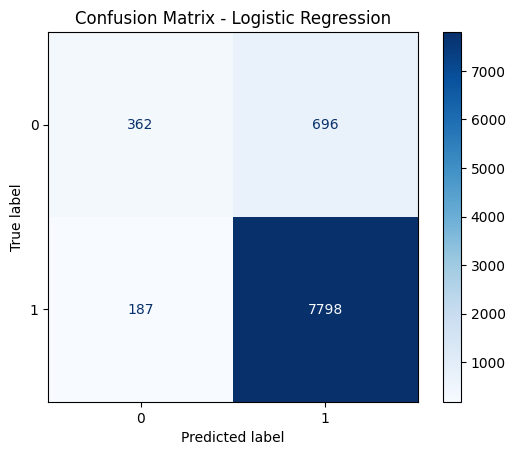

In [179]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_log)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")

plt.show()

### Interpretation

The confusion matrix shows how well the Logistic Regression model classified the test data. Most predictions are correct, while the incorrect predictions represent the model's classification errors.

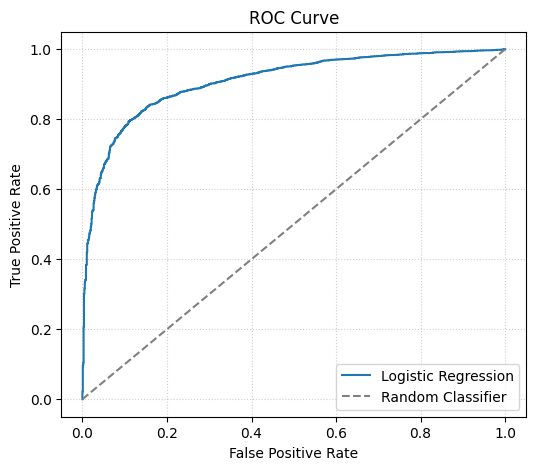

In [180]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# 1. Get predicted probabilities using SCALED test data
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

# 2. Compute ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_log)

# 3. Plot ROC Curve
plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random Classifier")  # Visual reference line

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)  # Optional: adds gridlines for better readability

plt.show()

### Interpretation

The ROC curve shows the ability of the Logistic Regression model to distinguish between the two classes. A curve closer to the top-left corner indicates better classification performance.

# 9. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In [181]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Random Forest Training

A Random Forest classifier was trained using the training dataset. The model learns from multiple decision trees to improve prediction accuracy and reduce overfitting.

In [182]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:,1]

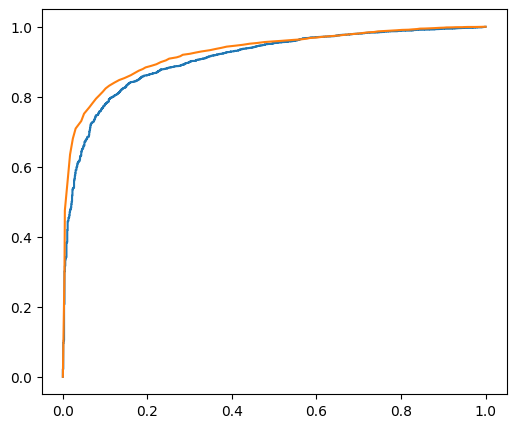

In [183]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot(fpr_rf, tpr_rf, label="Random Forest")

### Interpretation

The ROC curves compare the performance of the Logistic Regression and Random Forest models. The model with the curve closer to the top-left corner has better classification performance.

# 10. Random Forest Evaluation

The Random Forest model is evaluated using multiple classification metrics to measure its predictive performance.

In [184]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_rf))

Accuracy : 0.9026871613402632
Precision: 0.9242804251761615
Recall   : 0.9691922354414527
F1 Score : 0.9462036923829319
ROC AUC  : 0.9270980086717415


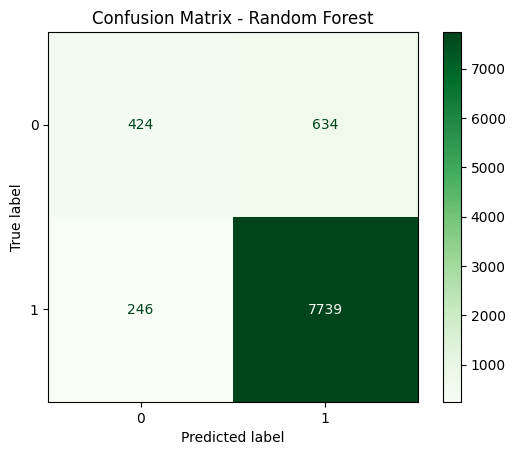

In [185]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)

disp.plot(cmap="Greens")

plt.title("Confusion Matrix - Random Forest")

plt.show()

### Interpretation

The confusion matrix shows how well the Random Forest model classified the test data. A higher number of correct predictions and fewer misclassifications indicate better model performance.

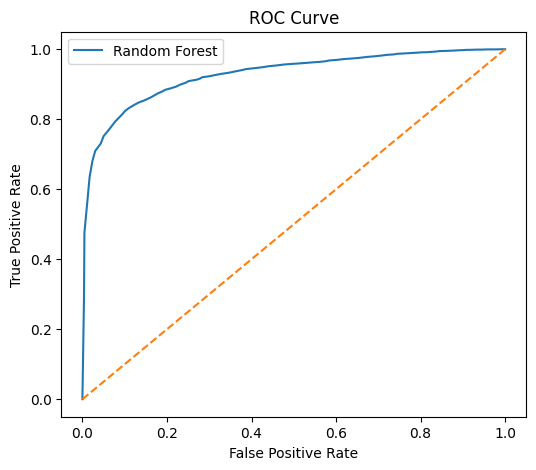

In [186]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(6,5))

plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

### Interpretation

The ROC curve shows how well the Random Forest model distinguishes between the two classes. A curve closer to the top-left corner indicates better classification performance.

# 11. Model Comparison

The performance of the Logistic Regression and Random Forest models is compared using the evaluation metrics.

In [187]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.902355,0.91806,0.976581,0.946417,0.908895
1,Random Forest,0.902687,0.92428,0.969192,0.946204,0.927098


# 12. Feature Importance

Feature importance identifies the variables that contribute the most to the Random Forest model's predictions.

In [188]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
3,duration,0.270709
1,balance,0.099057
2,day,0.085215
0,age,0.084444
38,poutcome_success,0.049833
5,pdays,0.040076
4,campaign,0.039137
22,housing_yes,0.021618
6,previous,0.020735
32,month_mar,0.014748


### Feature Importance

The importance scores of all features were calculated using the trained Random Forest model. The features were then sorted in descending order to identify the top 10 most influential predictors.

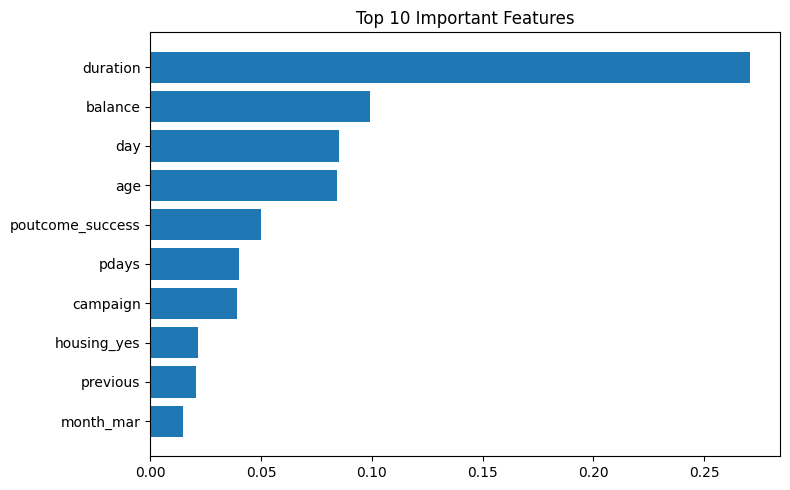

In [189]:
top10 = importance.head(10)

plt.figure(figsize=(8,5))

plt.barh(
    top10["Feature"],
    top10["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 10 Important Features")

plt.tight_layout()

plt.show()

### Interpretation

The bar chart displays the 10 most important features identified by the Random Forest model. Features with higher importance values contribute more to the model's predictions.

# 13. Recommendation

Based on the analysis and machine learning results:

- Focus marketing campaigns on customer groups with higher subscription likelihood.
- Give special attention to important features such as call duration and previous campaign outcome.
- Use the better-performing model to support customer targeting and improve campaign efficiency.

# 14. Conclusion

This project analyzed customer behavior using data preprocessing, exploratory data analysis, and machine learning techniques.

Two classification models were developed and evaluated to predict customer subscription behavior. The comparison showed that machine learning can effectively support marketing decisions by identifying customers with a higher probability of subscribing to a term deposit.

The insights obtained from this project can help banks optimize marketing campaigns, improve customer targeting, and increase overall campaign success.